# **Delhivery - Feature Engineering**
--- 
Business Case Study ~by **Shivaling Battarki (shivalingb09@gmail.com)**

> **About Delhivery**

- Delhivery is the largest and fastest-growing fully integrated player in India by revenue in Fiscal 2021. They aim to build the operating system for commerce, through a combination of world-class infrastructure, logistics operations of the highest quality, and cutting-edge engineering and technology capabilities.

## 1. **Problem Statement**
- The Data team builds intelligence and capabilities using this data that helps them to widen the gap between the quality, efficiency, and profitability of their business versus their competitors.
- Data coming out engineering pipelines is messy and needs to be cleaned, process, engineered to produce insights and make sense out of the data. the data needs to be transformed so thast the Data Teams can be build forecasting models based on it.
- Data from warehouse scanners and GPS pings arrives in fragmented, nested rows. Checkpoint scans do not represent customer deliveries. Delhivery's routing engine (OSRM) predicts transit times based on open road networks. These predictions often mismatch real road conditions.
- Project Goals
    - Clean and consolidate raw scanner logs into distinct Origin-Destination trips.
    - Build domain features from location text, facility codes, and timestamps.
    - Statistically test the accuracy of the OSRM routing engine against real ground truth.
    - Treat extreme outliers without losing genuine long-haul interstate shipments.
    - Encode and scale features for downstream machine learning models without data leakage.
    - Deliver non-technical, data-backed operational actions for business leadership.

## 2. Library Import and Data Loading

In [6]:
# Import essential data analytics and visualisation, statistical libraries 
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [7]:
# Cinfigure visual styling 
sns.set_theme(style='darkgrid', context='paper')
pd.set_option('display.max_columns', None  )
pd.set_option('display.float_format', lambda x: '%.3f' % x)
plt.rcParams.update({
    'font.size': 10,          # General/default font size
    'axes.titlesize': 10,     # Title size
    'axes.labelsize': 10,     # X and Y axis label size
    'xtick.labelsize': 10,    # X tick label size
    'ytick.labelsize': 10,    # Y tick label size
    'legend.fontsize': 8     # Legend font size
})

In [8]:
import os

file_path = 'delhivery_data.csv'

# Step 1: Check if dataset is already saved locally (VS Code / local Jupyter)
if os.path.exists(file_path):
    print(f"✅ Found '{file_path}' locally. Skipping download.")
else:
    # Step 2: If not found, download from Google Drive (Google Colab / Kaggle)
    print(f"⏳ '{file_path}' not found locally. Downloading from Google Drive...")
    try:
        import gdown
    except ImportError:
        import subprocess, sys
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gdown"])
        import gdown

    file_id = '1U_E1MzIyVf4AHj4hQNZQuGyOocCyQ0nN'
    gdown.download(id=file_id, output=file_path, quiet=False)
    print("✅ Dataset downloaded successfully!")

✅ Found 'delhivery_data.csv' locally. Skipping download.


In [9]:
# Load th e dataset into a pandas DataFrame
df = pd.read_csv('delhivery_data.csv')
print("Dataset loaded successfully!")
print(f'Dataset dimensioins: {df.shape[0]} rows and {df.shape[1]} columns')

Dataset loaded successfully!
Dataset dimensioins: 144867 rows and 24 columns


## 3. Exploratory Data Analysis

### 3.1 Environment Setup & Helper Utilities
> **Note for Colab Users:**  
> This notebook uses a custom helper module `eda_tools.py` for structured EDA, distributions, and summary metrics.  
> The cell below automatically detects Google Colab and downloads `eda_tools.py` into the session runtime so the notebook executes end-to-end without any manual configuration.

In [10]:
import os
import sys
import urllib.request

# Step 1: Check if eda_tools is already available locally (VS Code / local Jupyter)
try:
    from eda_tools import profile_data
    print("✅ eda_tools loaded from local environment.")

except ImportError:
    # Step 2: If not found, automatically download from GitHub (Google Colab / Kaggle)
    print("⏳ eda_tools not found locally. Downloading from GitHub...")
    
    current_dir = os.getcwd()
    if current_dir not in sys.path:
        sys.path.insert(0, current_dir)
        
    target_file = os.path.join(current_dir, "eda_tools.py")
    github_url = "https://raw.githubusercontent.com/Hazardous9hub/EDA-Data-Profile-Tool/main/eda_tools.py"
    
    try:
        urllib.request.urlretrieve(github_url, target_file)
        from eda_tools import profile_data
        print("✅ eda_tools downloaded and loaded successfully!")
    except Exception as e:
        print(f"❌ Could not download eda_tools: {e}")
        print("💡 Hint for Kaggle: Make sure 'Internet' is switched ON in the right-hand panel (Settings -> Internet -> ON).")

✅ eda_tools loaded from local environment.


In [11]:
# Use the profile_data function to generate a comprehensive data profile report
profile_data(df) 

,Data Type,Non-Null Count,Null Count,Null %,Unique Count,Sample Value
data,str,"144,867",0,0.00%,2,training
trip_creation_time,str,"144,867",0,0.00%,"14,817",2018-09-20 02:35:36.476840
route_schedule_uuid,str,"144,867",0,0.00%,"1,504",thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3297ef
route_type,str,"144,867",0,0.00%,2,Carting
trip_uuid,str,"144,867",0,0.00%,"14,817",trip-153741093647649320
source_center,str,"144,867",0,0.00%,"1,508",IND388121AAA
source_name,str,"144,574",293,0.20%,"1,498",Anand_VUNagar_DC (Gujarat)
destination_center,str,"144,867",0,0.00%,"1,481",IND388620AAB
destination_name,str,"144,606",261,0.18%,"1,468",Khambhat_MotvdDPP_D (Gujarat)
od_start_time,str,"144,867",0,0.00%,"26,369",2018-09-20 03:21:32.418600


,count,mean,std,min,50%,max
start_scan_to_end_scan,144867.000,961.260,1037.010,20.000,449.000,7898.000
cutoff_factor,144867.000,232.930,344.760,9.000,66.000,1927.000
actual_distance_to_destination,144867.000,234.070,344.990,9.000,66.130,1927.450
actual_time,144867.000,416.930,598.100,9.000,132.000,4532.000
osrm_time,144867.000,213.870,308.010,6.000,64.000,1686.000
osrm_distance,144867.000,284.770,421.120,9.010,78.530,2326.200
factor,144867.000,2.120,1.720,0.140,1.860,77.390
segment_actual_time,144867.000,36.200,53.570,-244.000,29.000,3051.000
segment_osrm_time,144867.000,18.510,14.780,0.000,17.000,1611.000
segment_osrm_distance,144867.000,22.830,17.860,0.000,23.510,2191.400


,data,trip_creation_time,route_schedule_uuid,route_type,trip_uuid,source_center,source_name,destination_center,destination_name,od_start_time,od_end_time,start_scan_to_end_scan,is_cutoff,cutoff_factor,cutoff_timestamp,actual_distance_to_destination,actual_time,osrm_time,osrm_distance,factor,segment_actual_time,segment_osrm_time,segment_osrm_distance,segment_factor
0,training,2018-09-20 02:35:36.476840,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),2018-09-20 03:21:32.418600,2018-09-20 04:47:45.236797,86.000,True,9,2018-09-20 04:27:55,10.436,14.000,11.000,11.965,1.273,14.000,11.000,11.965,1.273
1,training,2018-09-20 02:35:36.476840,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),2018-09-20 03:21:32.418600,2018-09-20 04:47:45.236797,86.000,True,18,2018-09-20 04:17:55,18.937,24.000,20.000,21.724,1.200,10.000,9.000,9.759,1.111
2,training,2018-09-20 02:35:36.476840,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),2018-09-20 03:21:32.418600,2018-09-20 04:47:45.236797,86.000,True,27,2018-09-20 04:01:19.505586,27.637,40.000,28.000,32.539,1.429,16.000,7.000,10.815,2.286
3,training,2018-09-20 02:35:36.476840,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),2018-09-20 03:21:32.418600,2018-09-20 04:47:45.236797,86.000,True,36,2018-09-20 03:39:57,36.118,62.000,40.000,45.562,1.550,21.000,12.000,13.022,1.750
4,training,2018-09-20 02:35:36.476840,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),2018-09-20 03:21:32.418600,2018-09-20 04:47:45.236797,86.000,False,39,2018-09-20 03:33:55,39.386,68.000,44.000,54.218,1.545,6.000,5.000,3.915,1.200


ℹ️ Profile complete: 24 features inspected.


Since the % of missing values in source_name and destination _name is 0.38%< 1% and just 551 rows we can drop those rows to avoid any analysis confusions, noise and to avoid introducing synthetic 'Unknown' Categories

### 3.2 Data Pre-processing

In [8]:
# Convert all potential datetime columns to datetime format for consistency and analysis
datetime_columns = ['trip_creation_time', 'od_start_time', 'od_end_time', 'cutoff_timestamp']

for col in datetime_columns:
    df[col] = pd.to_datetime(df[col], format = 'ISO8601')  # Convert to datetime, coerce errors to NaT

# Convert categorical columns to 'category' dtype for memory efficiency and analysis
categorical_columns = ['data', 'route_type']
for col in categorical_columns:
    df[col] = df[col].astype('category')

df.dtypes # Display the data types of all columns

data                                    category
trip_creation_time                datetime64[us]
route_schedule_uuid                          str
route_type                              category
trip_uuid                                    str
source_center                                str
source_name                                  str
destination_center                           str
destination_name                             str
od_start_time                     datetime64[us]
od_end_time                       datetime64[us]
start_scan_to_end_scan                   float64
is_cutoff                                   bool
cutoff_factor                              int64
cutoff_timestamp                  datetime64[us]
actual_distance_to_destination           float64
actual_time                              float64
osrm_time                                float64
osrm_distance                            float64
factor                                   float64
segment_actual_time 

In [9]:
# rows where only source_name are null
df[df['source_name'].isnull() & df['destination_name'].notnull()].shape


(290, 24)

In [10]:
# rows where only destination_name is null
df[df['destination_name'].isnull() & df['source_name'].notnull()].shape

(258, 24)

In [11]:
# rows wherte source_name and destination_name both are null
df[df['source_name'].isnull() & df['destination_name'].isnull()].shape


(3, 24)

In [12]:
# Drop rows where both source_name and destination_name are null, as they provide no useful information for analysis
initial_shape = df.shape

df.dropna(subset=['source_name', 'destination_name'], inplace = True)

dropped_rows = initial_shape[0] - df.shape[0]

print(f"Initial dataset dimensions: {initial_shape[0]} rows and {initial_shape[1]} columns")
print(f"Dropped {dropped_rows} rows ({(dropped_rows / initial_shape[0]) * 100:.2f}%) where both source_name and destination_name were null.")
print(f"New dataset dimensions: {df.shape[0]} rows and {df.shape[1]} columns")

Initial dataset dimensions: 144867 rows and 24 columns
Dropped 551 rows (0.38%) where both source_name and destination_name were null.
New dataset dimensions: 144316 rows and 24 columns


In [13]:
df.isnull().sum()

data                              0
trip_creation_time                0
route_schedule_uuid               0
route_type                        0
trip_uuid                         0
source_center                     0
source_name                       0
destination_center                0
destination_name                  0
od_start_time                     0
od_end_time                       0
start_scan_to_end_scan            0
is_cutoff                         0
cutoff_factor                     0
cutoff_timestamp                  0
actual_distance_to_destination    0
actual_time                       0
osrm_time                         0
osrm_distance                     0
factor                            0
segment_actual_time               0
segment_osrm_time                 0
segment_osrm_distance             0
segment_factor                    0
dtype: int64

In [14]:
# Now we have cleaned our dataset by removing rows with null values in both source_name and destination_name. The next steps would involve further data cleaning, feature engineering, and analysis based on the specific objectives of the case study.

### 3.3 Row Aggregations/Merge

In [15]:
# transforming the granular checkpoints an logs into clean analytical datasets 
# Total sub trips can be derived by grouping the data by trip_uuid, source_center, and destination_center. For each group, we can aggregate relevant metrics such as trip creation time, route type, source and destination names, start and end times, distances, and times. The aggregation functions used will depend on the nature of the data and the specific analysis requirements.

sub_trip_aggs = {
    'data': 'first',
    'trip_creation_time': 'first',
    'route_type': 'first',
    'source_name': 'first',
    'destination_name': 'first',
    'od_start_time': 'first',
    'od_end_time': 'first',
    'start_scan_to_end_scan': 'max',
    'actual_distance_to_destination': 'max',
    'actual_time': 'max',
    'osrm_time': 'max',
    'osrm_distance': 'max',
    'segment_actual_time': 'sum',
    'segment_osrm_time': 'sum',
    'segment_osrm_distance': 'sum'
} 

sub_trip_df = df.groupby(['trip_uuid', 'source_center', 'destination_center']).agg(sub_trip_aggs).reset_index()

print(f"sub_trip_df dataset dimensions: {sub_trip_df.shape[0]} rows and {sub_trip_df.shape[1]} columns")
print(f"Total Sub trips: {sub_trip_df.shape[0]}")

sub_trip_df.sort_values(by = ['trip_uuid', 'trip_creation_time', 'od_start_time'], inplace=True)
print('First few lines of sub_trip_df:')
display(sub_trip_df.head())

sub_trip_df dataset dimensions: 26222 rows and 18 columns
Total Sub trips: 26222
First few lines of sub_trip_df:


,trip_uuid,source_center,destination_center,data,trip_creation_time,route_type,source_name,destination_name,od_start_time,od_end_time,start_scan_to_end_scan,actual_distance_to_destination,actual_time,osrm_time,osrm_distance,segment_actual_time,segment_osrm_time,segment_osrm_distance
1,trip-153671041653548748,IND462022AAA,IND209304AAA,training,2018-09-12 00:00:16.535741,FTL,Bhopal_Trnsport_H (Madhya Pradesh),Kanpur_Central_H_6 (Uttar Pradesh),2018-09-12 00:00:16.535741,2018-09-12 16:39:46.858469,999.000,440.974,830.000,394.000,544.803,820.000,474.000,649.853
0,trip-153671041653548748,IND209304AAA,IND000000ACB,training,2018-09-12 00:00:16.535741,FTL,Kanpur_Central_H_6 (Uttar Pradesh),Gurgaon_Bilaspur_HB (Haryana),2018-09-12 16:39:46.858469,2018-09-13 13:40:23.123744,1260.000,383.759,732.000,349.000,446.550,728.000,534.000,670.620
3,trip-153671042288605164,IND572101AAA,IND561203AAB,training,2018-09-12 00:00:22.886430,Carting,Tumkur_Veersagr_I (Karnataka),Doddablpur_ChikaDPP_D (Karnataka),2018-09-12 00:00:22.886430,2018-09-12 02:03:09.655591,122.000,48.543,96.000,42.000,56.912,95.000,39.000,55.990
2,trip-153671042288605164,IND561203AAB,IND562101AAA,training,2018-09-12 00:00:22.886430,Carting,Doddablpur_ChikaDPP_D (Karnataka),Chikblapur_ShntiSgr_D (Karnataka),2018-09-12 02:03:09.655591,2018-09-12 03:01:59.598855,58.000,24.644,47.000,26.000,28.199,46.000,26.000,28.200
5,trip-153671043369099517,IND562132AAA,IND000000ACB,training,2018-09-12 00:00:33.691250,FTL,Bangalore_Nelmngla_H (Karnataka),Gurgaon_Bilaspur_HB (Haryana),2018-09-12 00:00:33.691250,2018-09-14 03:40:17.106733,3099.000,1689.965,2736.000,1529.000,2090.874,2700.000,1710.000,2227.527


In [16]:
# Full Trip dataset can be derived by grouping the data by trip_uuid. For each group, we can aggregate relevant metrics such as trip creation time, route type, source and destination names, start and end times, distances, and times. The aggregation functions used will depend on the nature of the data and the specific analysis requirements.

trip_aggs= {
    'data': 'first',
    'source_center': 'first',
    'destination_center': 'last',
    'trip_creation_time': 'first',
    'route_type': 'first',
    'source_name': 'first',
    'destination_name': 'last',
    'od_start_time': 'first',
    'od_end_time': 'last',
    'start_scan_to_end_scan': 'sum',
    'actual_distance_to_destination': 'sum',
    'actual_time': 'sum',
    'osrm_time': 'sum',
    'osrm_distance': 'sum',
    'segment_actual_time': 'sum',
    'segment_osrm_time': 'sum',
    'segment_osrm_distance': 'sum'
}

trip_df = sub_trip_df.groupby('trip_uuid').agg(trip_aggs).reset_index()

print(f"trip_df dataset dimensions: {trip_df.shape[0]} rows and {trip_df.shape[1]} columns")
print(f"Total trips: {trip_df.shape[0]}")

print('First few rows of trip_df:')
display(trip_df.head())

trip_df dataset dimensions: 14787 rows and 18 columns
Total trips: 14787
First few rows of trip_df:


,trip_uuid,data,source_center,destination_center,trip_creation_time,route_type,source_name,destination_name,od_start_time,od_end_time,start_scan_to_end_scan,actual_distance_to_destination,actual_time,osrm_time,osrm_distance,segment_actual_time,segment_osrm_time,segment_osrm_distance
0,trip-153671041653548748,training,IND462022AAA,IND000000ACB,2018-09-12 00:00:16.535741,FTL,Bhopal_Trnsport_H (Madhya Pradesh),Gurgaon_Bilaspur_HB (Haryana),2018-09-12 00:00:16.535741,2018-09-13 13:40:23.123744,2259.000,824.733,1562.000,743.000,991.352,1548.000,1008.000,1320.473
1,trip-153671042288605164,training,IND572101AAA,IND562101AAA,2018-09-12 00:00:22.886430,Carting,Tumkur_Veersagr_I (Karnataka),Chikblapur_ShntiSgr_D (Karnataka),2018-09-12 00:00:22.886430,2018-09-12 03:01:59.598855,180.000,73.187,143.000,68.000,85.111,141.000,65.000,84.189
2,trip-153671043369099517,training,IND562132AAA,IND160002AAC,2018-09-12 00:00:33.691250,FTL,Bangalore_Nelmngla_H (Karnataka),Chandigarh_Mehmdpur_H (Punjab),2018-09-12 00:00:33.691250,2018-09-14 17:34:55.442454,3933.000,1932.274,3347.000,1741.000,2372.085,3308.000,1941.000,2545.268
3,trip-153671046011330457,training,IND400072AAB,IND401104AAA,2018-09-12 00:01:00.113710,Carting,Mumbai Hub (Maharashtra),Mumbai_MiraRd_IP (Maharashtra),2018-09-12 00:01:00.113710,2018-09-12 01:41:29.809822,100.000,17.175,59.000,15.000,19.680,59.000,16.000,19.877
4,trip-153671052974046625,training,IND583101AAA,IND583101AAA,2018-09-12 00:02:09.740725,FTL,Bellary_Dc (Karnataka),Bellary_Dc (Karnataka),2018-09-12 00:02:09.740725,2018-09-12 12:00:30.683231,717.000,127.448,341.000,117.000,146.792,340.000,115.000,146.792


In [17]:
df['trip_uuid'].nunique() == trip_df.shape[0]

True

In [18]:
# We have now successfully transformed the granular checkpoints and logs into clean analytical datasets: `sub_trip_df` for sub trips and `trip_df` for full trips. These datasets can now be used for further analysis, feature engineering, and modeling as required.
# The data pre processing steps here gives the Trips Hierarchy feature and provides a solid foundation for subsequent analysis and modeling tasks.
# There are total 14,787 no. of Trips  and 26,222 no. of Sub trips in the dataset.

## 4. Data Cleaning and Feature Engineering

### 4.1 Extracting Geograhical detail features from `source_name` and `destination_name`

In [19]:
# Extracting City, Place, Code, State from the source_name and destination_name columns for further analysis and feature engineering. This can help in understanding the geographical distribution of trips and sub trips, as well as in identifying patterns or trends based on location.
# Extracting details from trip_df will give us true end-to-end delivery corridor information for each trip, which can be valuable for route optimization, logistics planning, and other operational insights.

# Extracting state inside parenthesis from `city_place_code (state)`
def extract_state(series):
    state = series.str.rsplit('(').str[1].str.strip(')')    # split from right side to get state inside ()
    return state.fillna('Unknown')          # fill any Null values with 'Unknown'

# Extracting cities from `city_place_code (state)`
def extract_city(series):
    city = series.str.replace(r'\(.*?\)', '', regex=True).str.strip().str.split('_', n = 3).str[0].str.strip()
    return city.fillna('Unknown')      # gives the city at first index

# Extarcting places from `city_place_code (state)`
def extract_place(series):
    place = series.str.replace(r'\(.*?\)', '', regex = True).str.strip().str.split('_', n = 3).str[1]
    return place.fillna('Unknown')

# Extacting codes from `city_place_code (state)` fro Hub info
def extract_code(series):
    code = series.str.replace(r'\(.*?\)', '', regex = True).str.strip().str.split('_', n = 3).str[2]
    return code.fillna('Others')

In [20]:
# Applying extraction functions to extarct city, palces, code and state from source_name and destination_name accordingly

# apply extract_state to source_name and destination_name
trip_df[['source_state', 'destination_state']] = (
    trip_df[['source_name','destination_name']].apply(extract_state)
)

# apply extract_city to source_name and destination_name
trip_df[['source_city', 'destination_city']] = (
    trip_df[['source_name','destination_name']].apply(extract_city)
)

# apply extract_place to source_name and destination_name
trip_df[['source_place', 'destination_place']] = (
    trip_df[['source_name','destination_name']].apply(extract_place)
)

# apply extract_code to source_name and destination_name
trip_df[['source_code', 'destination_code']] = (
    trip_df[['source_name','destination_name']].apply(extract_code)
)


In [21]:
# Glimpse of geographical features extarcted from source_name and destination_name

display(trip_df[['source_city', 'source_place', 'source_code', 'source_state', 'destination_city', 'destination_place', 'destination_code', 'destination_state']].head())

print('Geographical deatils extracted using string manipualtion and regex function for Feature engineering')

,source_city,source_place,source_code,source_state,destination_city,destination_place,destination_code,destination_state
0,Bhopal,Trnsport,H,Madhya Pradesh,Gurgaon,Bilaspur,HB,Haryana
1,Tumkur,Veersagr,I,Karnataka,Chikblapur,ShntiSgr,D,Karnataka
2,Bangalore,Nelmngla,H,Karnataka,Chandigarh,Mehmdpur,H,Punjab
3,Mumbai Hub,Unknown,Others,Maharashtra,Mumbai,MiraRd,IP,Maharashtra
4,Bellary,Dc,Others,Karnataka,Bellary,Dc,Others,Karnataka


Geographical deatils extracted using string manipualtion and regex function for Feature engineering


### 4.2 Temporal Feature extraction and Trip Duration Calculation from `trip_creation_time`

In [22]:
# extract day and time feature from trip_cration_time

trip_df['trip_year'] = trip_df['trip_creation_time'].dt.year                            # year of the trip dispatch
trip_df['trip_month'] = trip_df['trip_creation_time'].dt.month_name()                   # month name of the trip dispatch 
trip_df['trip_day'] = trip_df['trip_creation_time'].dt.day                              # dispatch day of the month  (1 ~ 31)
trip_df['trip_hour'] = trip_df['trip_creation_time'].dt.hour                            # hour of departure (0 ~ 23)
trip_df['trip_day_name'] = trip_df['trip_creation_time'].dt.day_name()                  # Day of dispatch 
trip_df['is_weekend'] = trip_df['trip_creation_time'].dt.day_name().isin(['Saturday', 'Sunday']).astype(int)        # trip dispatch on weekend ?


In [23]:
# Trip Duration Feature
# Calculation of difference between od_start_time and od_end_time in minutes

trip_df['trip_duration_min'] = np.round((trip_df['od_end_time'] - trip_df['od_start_time']).dt.total_seconds() / 60, 0)
# converting to minutes comaprison and analysis consistent \

display(trip_df[['trip_year', 'trip_month', 'trip_day', 'trip_hour', 'trip_day_name', 'is_weekend', 'trip_duration_min']].head(3))

print('Temporal Features extarcted using Date and Time functions')  

,trip_year,trip_month,trip_day,trip_hour,trip_day_name,is_weekend,trip_duration_min
0,2018,September,12,0,Wednesday,0,2260.000
1,2018,September,12,0,Wednesday,0,182.000
2,2018,September,12,0,Wednesday,0,3934.000


Temporal Features extarcted using Date and Time functions


## 5. Comparison, Visual Analysis & Hypothesis Testing

### 5.1 Visual Exploratory Data Analysis for Continuous, Categorical Variables

In [24]:
# Distribution Analysis of Continuous Variables
# numerical columns for distribution, outliers, difference
num_cols = ['actual_time', 'osrm_time', 'actual_distance_to_destination', 'osrm_distance', 'trip_duration_min', 'start_scan_to_end_scan']
# categorical columns 
cat_cols = ['route_type', 'is_weekend', 'source_state', 'destination_state', 'source_city', 'destination_city']

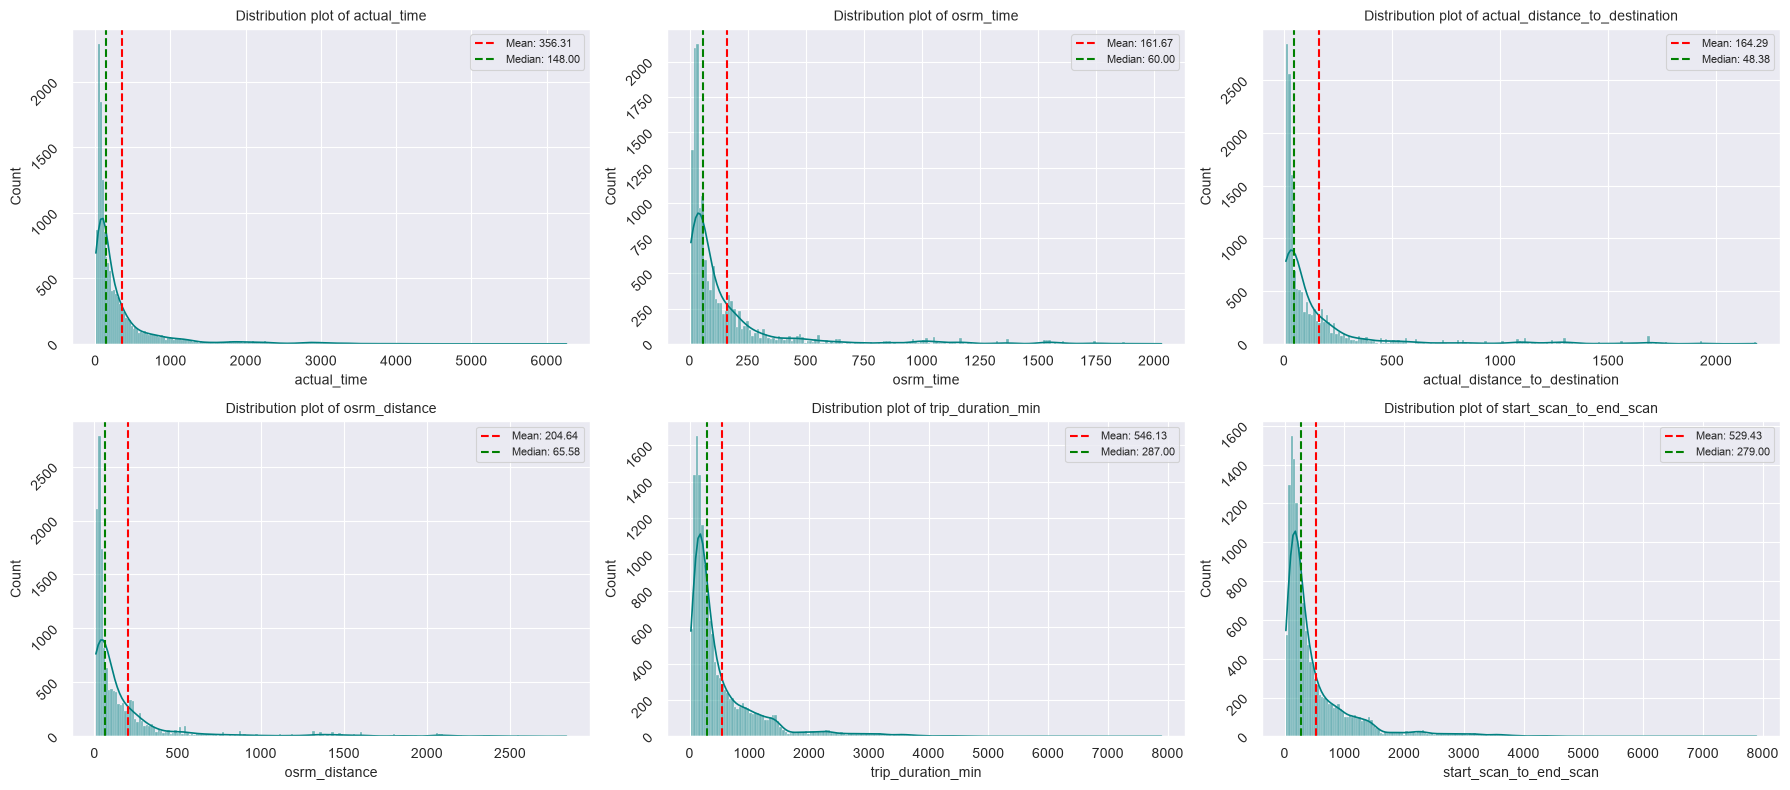

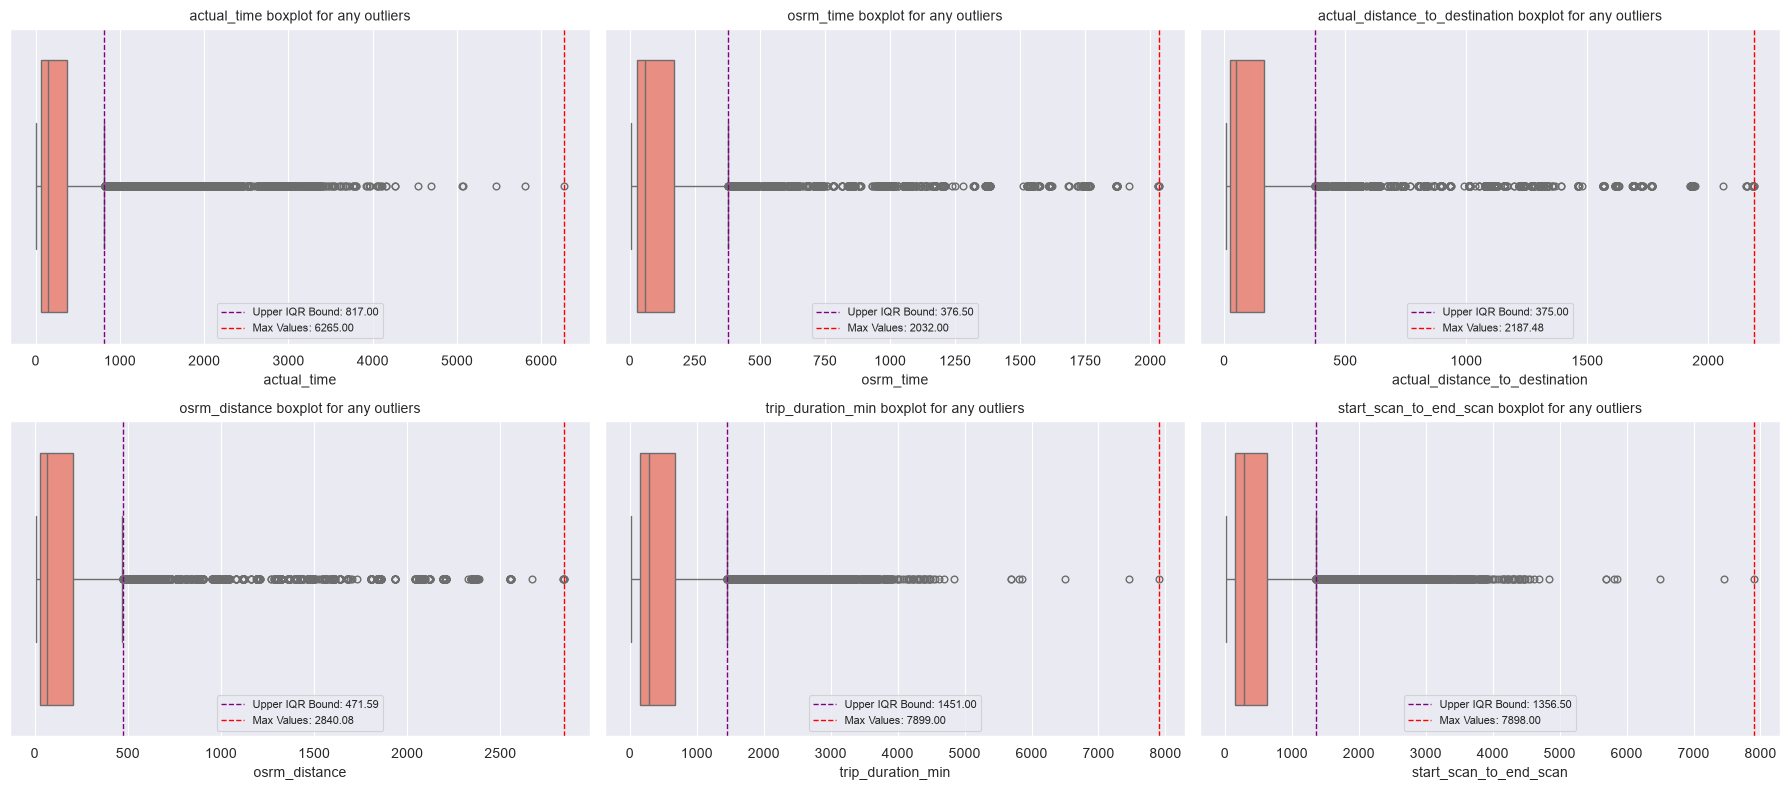

In [25]:
# UNIVARIATE Analysis

n_rows = 2
n_cols = 3
fig, axes = plt.subplots(n_rows, n_cols, figsize = (18, 4*n_rows) )
# Histograms for visual distribution 

for i, col in enumerate(num_cols):
    plt.subplot(n_rows, n_cols, i+1)
    sns.histplot(trip_df[col], kde = True, bins = 'auto', color = 'teal')
    plt.axvline(trip_df[col].mean(), color='red', linestyle='--', linewidth=1.5, label=f'Mean: {trip_df[col].mean():.2f}')
    plt.axvline(trip_df[col].median(), color='green', linestyle='--', linewidth=1.5, label=f'Median: {trip_df[col].median():.2f}')
    
    plt.title(f"Distribution plot of {col}")
    plt.yticks(rotation = 45)
    plt.legend()
    plt.tight_layout()

# boxplot for outliers validation
fig, axes = plt.subplots(n_rows, n_cols, figsize = (18, 4*n_rows) )
for i, col in enumerate(num_cols):
    # outlier deterction using IQR
    Q1 = trip_df[col].quantile(0.25)
    Q3 = trip_df[col].quantile(0.75)
    Q4 = trip_df[col].quantile(1.00)
    IQR = Q3 - Q1
    lower_bound = Q1 - IQR*1.5
    upper_bound = Q3 + IQR*1.5


    plt.subplot(n_rows, n_cols, i+1)
    sns.boxplot(x = trip_df[col], color = 'salmon')
    plt.axvline(upper_bound, color = 'purple', linestyle='--', linewidth=1, label = f'Upper IQR Bound: {upper_bound:.2f}')
    plt.axvline(Q4, color = 'red', linestyle='--', linewidth=1, label = f'Max Values: {Q4:.2f}')

    plt.title(f'{col} boxplot for any outliers')
    plt.legend()
    plt.tight_layout()

In [26]:
# The above histograms show right skewed distributions indicationg many outliers in variables
# boxplots verify the outliers in huge numbers
# These outliers are genuine data points which signify the true aspects of Trips, hence instead of removing them
# Capping of outliers to cliping them to upper bound can be implemented for durther analysis 
# Mean > Median for all distributions.

### 5.2 Visual Comaprison between Temporal Categorical Features  

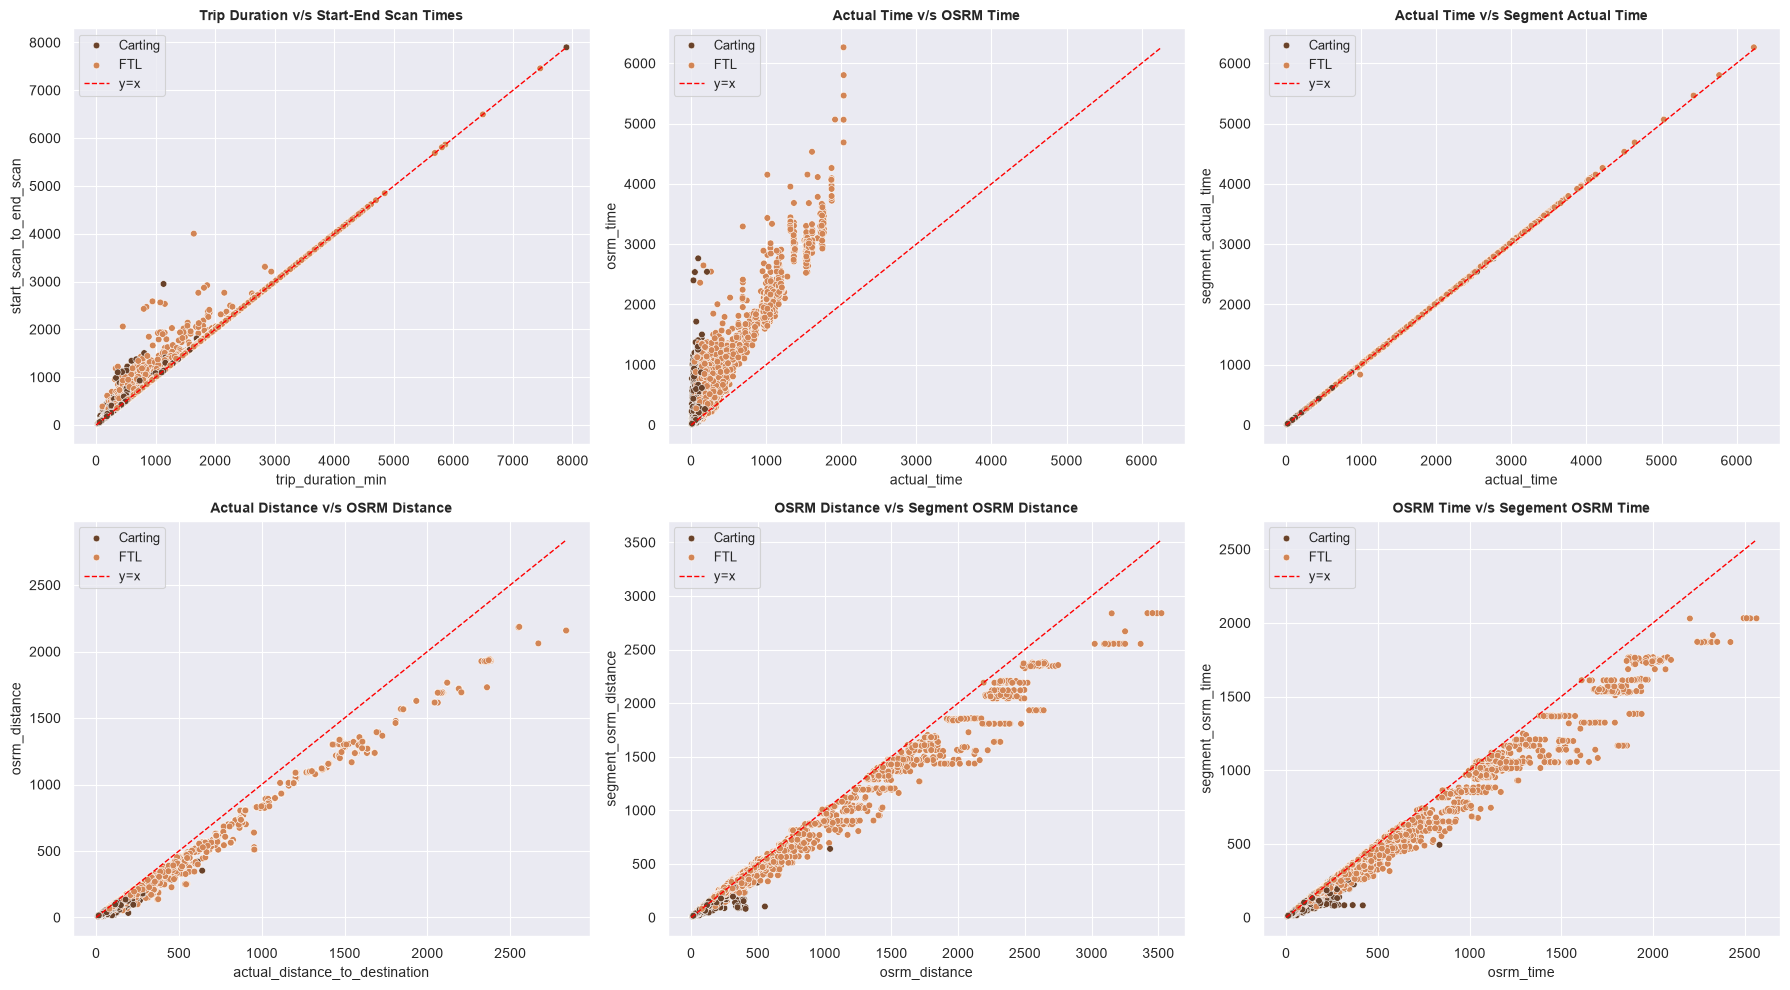

In [27]:
pairs = [
    ('trip_duration_min', 'start_scan_to_end_scan', 'Trip Duration v/s Start-End Scan Times'),
    ('actual_time', 'osrm_time', 'Actual Time v/s OSRM Time'),
    ('actual_time', 'segment_actual_time', 'Actual Time v/s Segment Actual Time'),
    ('actual_distance_to_destination', 'osrm_distance', 'Actual Distance v/s OSRM Distance'),
    ('osrm_distance', 'segment_osrm_distance', 'OSRM Distance v/s Segment OSRM Distance'),
    ('osrm_time', 'segment_osrm_time', 'OSRM Time v/s Segement OSRM Time')
]


n_rows = 2
n_cols = 3
plt.subplots(n_rows, n_cols, figsize = (18, 5*n_rows))

for i, (col_a, col_b, title) in enumerate(pairs):
    plt.subplot(n_rows, n_cols, i+1)
    # scatter plot
    sns.scatterplot(x = trip_df[col_b], y = trip_df[col_a], hue = trip_df['route_type'], palette = 'copper')

    # 45 degree reference line
    max_val = max(trip_df[col_a].max(), trip_df[col_b].max())
    plt.plot([0, max_val], [0, max_val], color = 'red', 
             linestyle = '--', linewidth = 1, label = 'y=x')

    plt.title(title, fontsize = 10, fontweight = 'bold')
    plt.xlabel(f'{col_a}')
    plt.ylabel(f'{col_b}')
    plt.legend(fontsize = 9)
    plt.tight_layout()

plt.show()



In [28]:
# The above Scatter plots show Significant difference from Actual and OSRM data readings.
# Let's us do hypothesis testings for same pairs to verify differences among the pairs and comapare the data

### 5.3 Hypothesis Testings
- H0: There is no significant difference between two variables (actual and osrm)
- Ha: There is a significant difference between two variables
- Confidence Level; 95% (0.95), Significance Level: alpha = 0.05

In [29]:
# For each pair, get the difference D = A -B, at 95% confidence level (alpha = 0.05, significance level)
# Normality Tests using shapiro
# Based on normality, test to be run:
    # if p_norm > 0.05 --> Paired t-tests
    # if p+norm < 0.05 --> Wilcoxon tests

# import the required Stats library
from scipy import stats
from scipy.stats import ttest_rel
from scipy.stats import wilcoxon
from scipy.stats import shapiro

In [30]:
# Normality checks and Hypothesis tests on `pairs`
# Use samples from trip_df columns difference in compliance with CLT
test_results = []

np.random.seed(42)
# using confidence level 95%
alpha = 0.05            # significance level

for col_a, col_b, title in pairs:

    diff = trip_df[col_a] - trip_df[col_b]
    
    # 1. Normality test on difference (sample size 5000)
    sample_diff = diff.sample(n = min(len(diff), 5000))
    s_stat, p_norm = shapiro(sample_diff)       # if p_norm > 0.05: Normal, else if p_norm < 0.05: Non normal 

    # 2. Select appropriate tests based on shapiro's p_norm
    if  p_norm > alpha:
        test_name = 'Parametric Paired t-test'
        # two-sided paired t-tests
        stat, p_val = ttest_rel(trip_df[col_a], trip_df[col_b])
    else: 
        test_name = 'Non-Parametric Wilcoxon Signed Rank test'
        stat, p_val = wilcoxon(trip_df[col_a], trip_df[col_b])

    test_results.append({
        'Comaprison': f'{col_a} v/s {col_b}',
        'Mean Difference (A-B)': np.round(diff.mean(), 2),
        'Median Difference': np.round(diff.median(), 2),
        'Normality p value': f'{p_norm:.2e}',
        'Stat Hypothesis Test': test_name,
        'Test p value': f'{p_val:.2e}',
        'Null Hypothesis (H0)': 'Rejected (Difference is significant)' if p_val < alpha else 'Failed to Reject (No significant difference)'
    })

hypothesis_results_df = pd.DataFrame(test_results)
display(hypothesis_results_df)



,Comaprison,Mean Difference (A-B),Median Difference,Normality p value,Stat Hypothesis Test,Test p value,Null Hypothesis (H0)
0,trip_duration_min v/s start_scan_to_end_scan,16.700,1.000,3.16e-89,Non-Parametric Wilcoxon Signed Rank test,0.00e+00,Rejected (Difference is significant)
1,actual_time v/s osrm_time,194.640,80.000,6.63e-76,Non-Parametric Wilcoxon Signed Rank test,0.00e+00,Rejected (Difference is significant)
2,actual_time v/s segment_actual_time,3.250,1.000,5.72e-78,Non-Parametric Wilcoxon Signed Rank test,0.00e+00,Rejected (Difference is significant)
3,actual_distance_to_destination v/s osrm_distance,-40.350,-13.260,2.07e-77,Non-Parametric Wilcoxon Signed Rank test,0.00e+00,Rejected (Difference is significant)
4,osrm_distance v/s segment_osrm_distance,-18.070,-0.880,2.69e-85,Non-Parametric Wilcoxon Signed Rank test,0.00e+00,Rejected (Difference is significant)
5,osrm_time v/s segment_osrm_time,-18.840,-1.000,1.01e-83,Non-Parametric Wilcoxon Signed Rank test,0.00e+00,Rejected (Difference is significant)


In [31]:
# All the paired comparisons using Hypothesis test confirm significant difference in Actual Scenario and OSRM readings

### Hypothesis Testing Conclusions
1. **Actual Delivery Time vs OSRM Engine (p < 0.001)**:
   - Reject H0. The difference is statistically significant.
   - Mean delivery time exceeds OSRM predictions by **194.6 minutes** (median difference: **80 minutes**).
   - OSRM is systematically optimistic. It does not account for real highway bottlenecks.

2. **Scan Duration vs Calculated Duration (p < 0.001)**:
   - Reject H0. Median difference is small (**1.0 minute**), but statistically significant due to terminal gate checkout lag.

3. **Cumulative Totals vs Segment Sums (p < 0.001)**:
   - Median difference is small (**~1.0 minute / 0.88 km**). This proves our hierarchical aggregation captured ground truth accurately.

### 5.4 Categorical & Spatial Exploration (Fleet & Geographical Patterns)

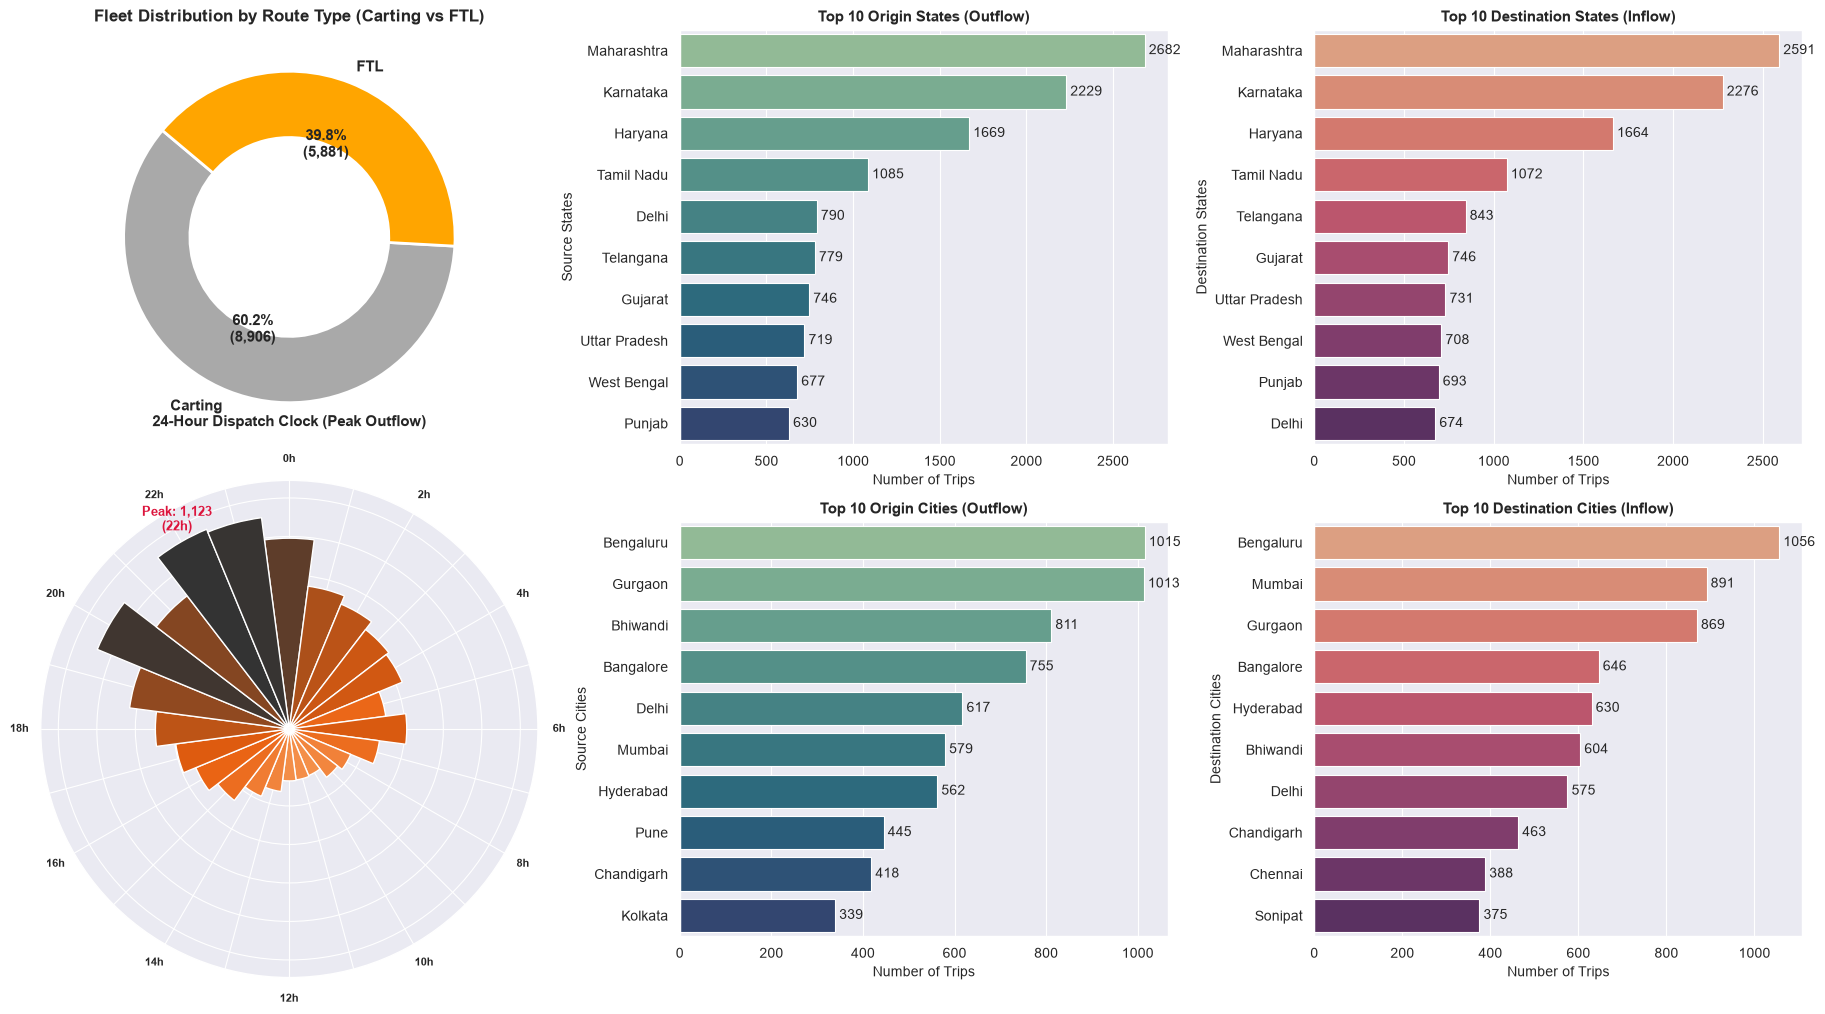

In [32]:
n_rows = 2
n_cols = 3
plt.figure(figsize = (18, 5*n_rows))

# Route Type Donut Chart
plt.subplot(n_rows, n_cols, 1)
route_counts = trip_df['route_type'].value_counts()
colors = ['darkgray', 'orange']
total_trips = route_counts.sum()
count_pct_label = lambda pct: f"{pct:.1f}%\n({int(round(pct * total_trips / 100)):,})"
# Pie with a hole (width=0.4 gives donut effect)
plt.pie(
    route_counts, 
    labels=route_counts.index, 
    autopct=count_pct_label, 
    startangle=140, 
    colors=colors , 
    wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2),
    textprops={'fontsize': 11, 'fontweight': 'bold'}
)
plt.title('Fleet Distribution by Route Type (Carting vs FTL)', fontsize=12, fontweight='bold')
plt.tight_layout()


# Top 10 Source States
plt.subplot(n_rows, n_cols, 2)
top_src_states = trip_df['source_state'].value_counts().head(10)
ax2 = sns.barplot(x=top_src_states.values, y=top_src_states.index, palette='crest')
for c in ax2.containers:
    ax2.bar_label(c, padding=3)
plt.title('Top 10 Origin States (Outflow)', fontsize=11, fontweight='bold')
plt.xlabel('Number of Trips')
plt.ylabel('Source States')

# Top 10 Destination States
plt.subplot(n_rows, n_cols, 3)
top_dst_states = trip_df['destination_state'].value_counts().head(10)
ax3 = sns.barplot(x=top_dst_states.values, y=top_dst_states.index, palette='flare')
for c in ax3.containers:
    ax3.bar_label(c, padding=3)
plt.title('Top 10 Destination States (Inflow)', fontsize=11, fontweight='bold')
plt.xlabel('Number of Trips')
plt.ylabel('Destination States')
plt.tight_layout()

# Top 10 Source Cities
plt.subplot(n_rows, n_cols, 5)
top_src_cities = trip_df['source_city'].value_counts().head(10)
ax2 = sns.barplot(x=top_src_cities.values, y=top_src_cities.index, palette='crest')
for c in ax2.containers:
    ax2.bar_label(c, padding=3)
plt.title('Top 10 Origin Cities (Outflow)', fontsize=11, fontweight='bold')
plt.xlabel('Number of Trips')
plt.ylabel('Source Cities')
plt.tight_layout()

# Top 10 Destination Cities
plt.subplot(n_rows, n_cols, 6)
top_dst_cities = trip_df['destination_city'].value_counts().head(10)
ax3 = sns.barplot(x=top_dst_cities.values, y=top_dst_cities.index, palette='flare')
for c in ax3.containers:
    ax3.bar_label(c, padding=3)
plt.title('Top 10 Destination Cities (Inflow)', fontsize=11, fontweight='bold')
plt.xlabel('Number of Trips')
plt.ylabel('Destination Cities')
plt.tight_layout()

# 24-Hour Circular Clock Bar Plot
ax6 = plt.subplot(n_rows, n_cols, 4, projection='polar')
# 1. Prepare 24-hour data
hourly_counts = trip_df['trip_hour'].value_counts().reindex(range(24), fill_value=0)
counts = hourly_counts.values
angles = np.linspace(0, 2 * np.pi, 24, endpoint=False)
width = (2 * np.pi) / 24
# 2. Clock orientation (Midnight at the TOP, clockwise)
ax6.set_theta_direction(-1)
ax6.set_theta_offset(np.pi / 2.0)
# 3. Colors
norm_counts = counts / counts.max()
colors = sns.color_palette('Oranges_d', as_cmap=True)(norm_counts)
# 4. Draw bars
bars = ax6.bar(angles, counts, width=width, bottom=0, color=colors, edgecolor='white', linewidth=1)
# 5. Find and highlight ONLY the MAX dispatch hour
max_idx = counts.argmax()
max_hour = hourly_counts.index[max_idx]
max_count = counts[max_idx]
max_angle = angles[max_idx]
# Single callout for the peak hour
ax6.text(
    max_angle, 
    max_count * 1.04, 
    f"Peak: {max_count:,}\n({max_hour}h)", 
    ha='center', 
    va='bottom', 
    fontsize=9, 
    fontweight='bold', 
    color='crimson'
)
# 6. MAKE IT BIGGER: Set tight ylim so bars expand outwards to fill the circle!
ax6.set_ylim(0, max_count * 1.15)
# 7. Hour tick labels
ax6.set_xticks(angles)
ax6.set_xticklabels([f'{h}h' if h % 2 == 0 else '' for h in range(24)], fontsize=8, fontweight='bold')
ax6.set_yticklabels([])  # Hide inner concentric number rings
plt.title('24-Hour Dispatch Clock (Peak Outflow)', fontsize=11, fontweight='bold', pad=20)
pos = ax6.get_position()
scale = 1.2  # Enlarges the circle by 25%!
new_w = pos.width * scale
new_h = pos.height * scale
ax6.set_position([pos.x0 - (new_w - pos.width)/2, pos.y0 - (new_h - pos.height)/2, new_w, new_h])


plt.show()

In [33]:
# Maharshtra State and Bengaluru City are top from where the Logistics operations are sourced and delivered.
# Majority of Trip Dispatch initiates during night i.e. around 10 PM (22:00 Hours)
# Cart trips dominate the logistics routr type than Full truck Loads

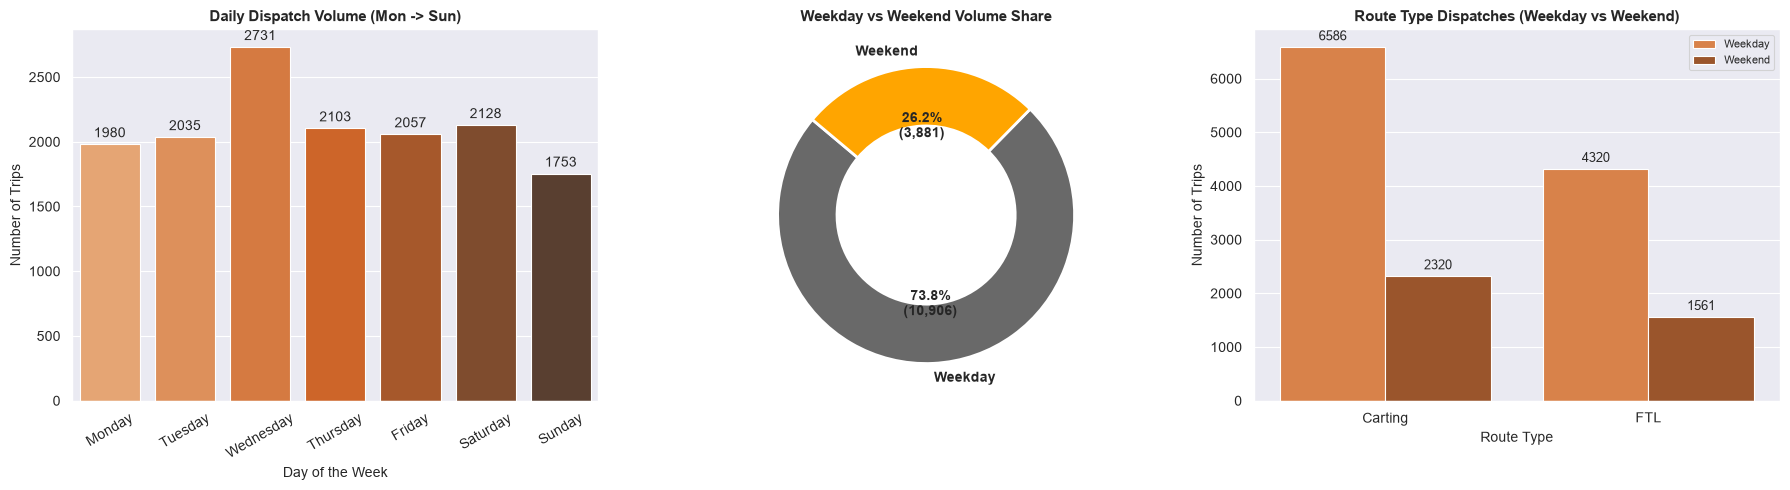

In [34]:
n_rows = 1
n_cols = 3
plt.figure(figsize=(18, 5 * n_rows))

# Daily Dispatch Trend (Monday to Sunday) 
plt.subplot(n_rows, n_cols, 1)
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
day_counts = trip_df['trip_day_name'].value_counts().reindex(days_order)

ax1 = sns.barplot(x=day_counts.index, y=day_counts.values, palette='Oranges_d')
for c in ax1.containers:
    ax1.bar_label(c, padding=3)
plt.title('Daily Dispatch Volume (Mon -> Sun)', fontsize=11, fontweight='bold')
plt.xlabel('Day of the Week')
plt.ylabel('Number of Trips')
plt.xticks(rotation=30)


# Weekday vs. Weekend Volume Split (Donut Chart)
plt.subplot(n_rows, n_cols, 2)
weekend_counts = trip_df['is_weekend'].map({0: 'Weekday', 1: 'Weekend'}).value_counts()
colors = ['dimgrey', 'orange']

total_wk = weekend_counts.sum()
count_pct_label = lambda pct: f"{pct:.1f}%\n({int(round(pct * total_wk / 100)):,})"

plt.pie(
    weekend_counts,
    labels=weekend_counts.index,
    autopct=count_pct_label,
    startangle=140,
    colors=colors,
    wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2),
    textprops={'fontsize': 10, 'fontweight': 'bold'}
)
plt.title('Weekday vs Weekend Volume Share', fontsize=11, fontweight='bold')


# Fleet Route Type Split by Weekday vs. Weekend
plt.subplot(n_rows, n_cols, 3)
ax3 = sns.countplot(
    data = trip_df, 
    x = 'route_type', 
    hue = 'is_weekend', 
    palette = 'Oranges_d'
)
# Label bars
for container in ax3.containers:
    ax3.bar_label(container, padding=3, fontsize=9)

plt.title('Route Type Dispatches (Weekday vs Weekend)', fontsize=11, fontweight='bold')
plt.xlabel('Route Type')
plt.ylabel('Number of Trips')
plt.legend(['Weekday', 'Weekend'], title='')

plt.tight_layout()
plt.show()

In [35]:
# Trips are majorly dispatched during Weekdays (wednesday, thursday) ~73.8%, in Weekends less (~26.2%)
# Carting Route types domainate acroos all weekdays and weekends 

## 6. Outlier Profiling and Treatment (IQR Method)

### 6.1 Quantify Outliers and Capping
- Detect the outliers using IQR
- Cap the outliers using a copy of the dataset

In [36]:
# Quantify Outliers across all continuous variables
# Copy the trip_df and create another dataframe, this will keep the original data intact
# further
trip_df_treated = trip_df.copy()
trip_df_treated.drop(columns = ['source_name', 'destination_name'], inplace = True)
trip_df_treated.head()

,trip_uuid,data,source_center,destination_center,trip_creation_time,route_type,od_start_time,od_end_time,start_scan_to_end_scan,actual_distance_to_destination,actual_time,osrm_time,osrm_distance,segment_actual_time,segment_osrm_time,segment_osrm_distance,source_state,destination_state,source_city,destination_city,source_place,destination_place,source_code,destination_code,trip_year,trip_month,trip_day,trip_hour,trip_day_name,is_weekend,trip_duration_min
0,trip-153671041653548748,training,IND462022AAA,IND000000ACB,2018-09-12 00:00:16.535741,FTL,2018-09-12 00:00:16.535741,2018-09-13 13:40:23.123744,2259.000,824.733,1562.000,743.000,991.352,1548.000,1008.000,1320.473,Madhya Pradesh,Haryana,Bhopal,Gurgaon,Trnsport,Bilaspur,H,HB,2018,September,12,0,Wednesday,0,2260.000
1,trip-153671042288605164,training,IND572101AAA,IND562101AAA,2018-09-12 00:00:22.886430,Carting,2018-09-12 00:00:22.886430,2018-09-12 03:01:59.598855,180.000,73.187,143.000,68.000,85.111,141.000,65.000,84.189,Karnataka,Karnataka,Tumkur,Chikblapur,Veersagr,ShntiSgr,I,D,2018,September,12,0,Wednesday,0,182.000
2,trip-153671043369099517,training,IND562132AAA,IND160002AAC,2018-09-12 00:00:33.691250,FTL,2018-09-12 00:00:33.691250,2018-09-14 17:34:55.442454,3933.000,1932.274,3347.000,1741.000,2372.085,3308.000,1941.000,2545.268,Karnataka,Punjab,Bangalore,Chandigarh,Nelmngla,Mehmdpur,H,H,2018,September,12,0,Wednesday,0,3934.000
3,trip-153671046011330457,training,IND400072AAB,IND401104AAA,2018-09-12 00:01:00.113710,Carting,2018-09-12 00:01:00.113710,2018-09-12 01:41:29.809822,100.000,17.175,59.000,15.000,19.680,59.000,16.000,19.877,Maharashtra,Maharashtra,Mumbai Hub,Mumbai,Unknown,MiraRd,Others,IP,2018,September,12,0,Wednesday,0,100.000
4,trip-153671052974046625,training,IND583101AAA,IND583101AAA,2018-09-12 00:02:09.740725,FTL,2018-09-12 00:02:09.740725,2018-09-12 12:00:30.683231,717.000,127.448,341.000,117.000,146.792,340.000,115.000,146.792,Karnataka,Karnataka,Bellary,Bellary,Dc,Dc,Others,Others,2018,September,12,0,Wednesday,0,718.000


In [37]:
# numerical continuous columns to be treated for Outliers
num_cols = [
    'actual_time', 'osrm_time',
    'actual_distance_to_destination', 'osrm_distance',
    'trip_duration_min', 'start_scan_to_end_scan' 
]

# IQR method detection of outliers, boundaries, via loopinf columns in num_cols
for col in num_cols:
    Q1 = trip_df_treated[col].quantile(0.25)
    Q3 = trip_df_treated[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_limit = Q1 - IQR*1.5
    upper_limit = Q3 + IQR*1.5

    # cap values to bounds
    trip_df_treated[col] = trip_df_treated[col].clip(lower = lower_limit, upper = upper_limit)


### 6.2 Visual Verification for Outlier Treatment (before v/s after)

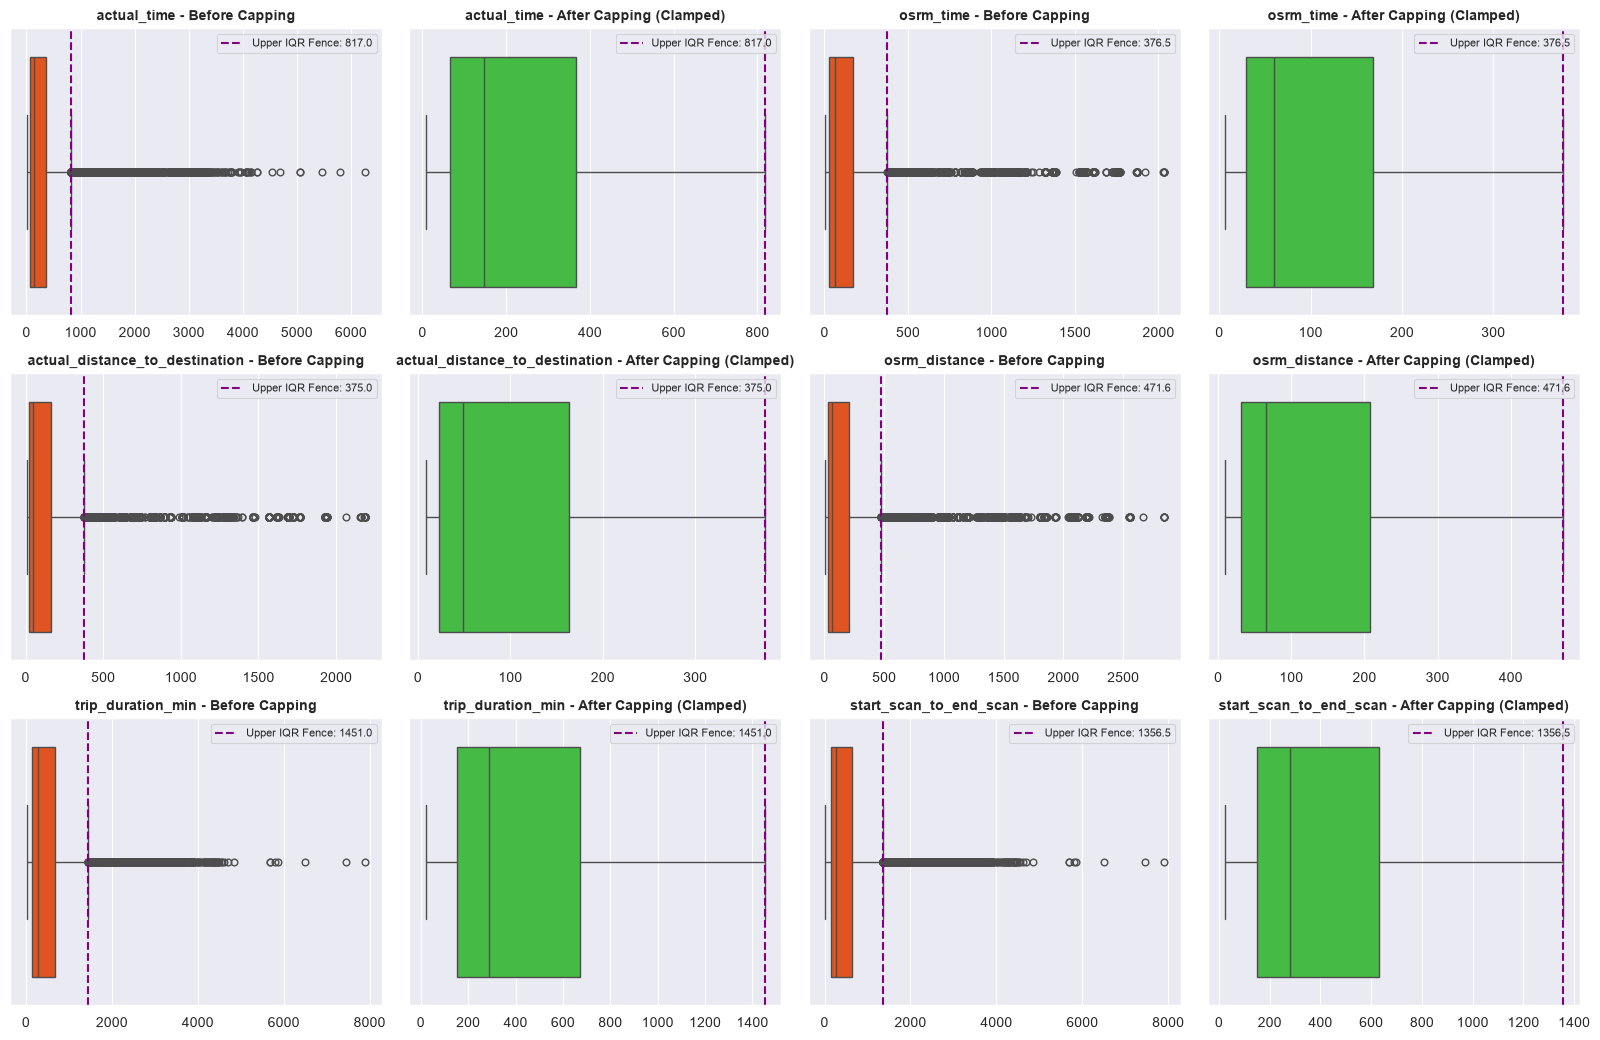

In [38]:
n_rows = 3  # 2 feature in a row
n_cols = 4  # before in 1st and 3rd and after in 2nd and 4th for respective 2 features

plt.figure(figsize=(16, 3.5 * n_rows))

for i, col in enumerate(num_cols):
    
    # Calculate upper limit for reference line
    Q1 = trip_df[col].quantile(0.25)
    Q3 = trip_df[col].quantile(0.75)
    IQR = Q3 - Q1
    upper_bound = Q3 + 1.5 * IQR

    # Left Plot: BEFORE Treatment (Subplot 2*i + 1)
    plt.subplot(n_rows, n_cols,  2*i + 1)
    sns.boxplot(x=trip_df[col], color='orangered')
    plt.axvline(upper_bound, color='purple', linestyle='--', linewidth=1.5, label=f'Upper IQR Fence: {upper_bound:.1f}')
    plt.title(f'{col} - Before Capping', fontsize=10, fontweight='bold')
    plt.xlabel('')
    plt.legend(loc='upper right', fontsize=8)

    # Right Plot: AFTER Treatment (Subplot 2*i + 2) 
    plt.subplot(n_rows, n_cols,  2*i + 2)
    sns.boxplot(x=trip_df_treated[col], color='limegreen')
    plt.axvline(upper_bound, color='purple', linestyle='--', linewidth=1.5, label=f'Upper IQR Fence: {upper_bound:.1f}')
    plt.title(f'{col} - After Capping (Clamped)', fontsize=10, fontweight='bold')
    plt.xlabel('')
    plt.legend(loc='upper right', fontsize=8)

plt.tight_layout()
plt.show()

In [39]:
# All the neccessary numerical columns have been capped to their upper bounds following Outlier treatment through IQR method


## 7. Categorical Encoding and Feature Scaling (for ML models)

### 7.1 One Hot Encoding 

In [40]:
# For teams to build forecasting models, the Machine Learning Models need categories properly encoded in numbers
# One Hoe Encoding helps to encode the categories numerically

# Define categorical columns to be encoded
cat_cols_encoded = ['route_type', 'trip_day_name', 'trip_month']

# apply One Hot Encoding with drop_first = True (avoid dummy)
trip_df_encoded = pd.get_dummies(
    trip_df_treated,
    columns = cat_cols_encoded,
    dtype = int
)

print(f'Original Shape: {trip_df_treated.shape[0]} rows and {trip_df_treated.shape[1]} columns')
print(f'Encoded Shape: {trip_df_encoded.shape[0]} rows and {trip_df_encoded.shape[1]} columns')

# Verify newly created dummy columns
dummy_cols = [c for c in trip_df_encoded.columns if any(c.startswith(prefix) for prefix in cat_cols_encoded)]
print(f"Total dummy features created: {len(dummy_cols)}")
display(trip_df_encoded[dummy_cols].head(3))

Original Shape: 14787 rows and 31 columns
Encoded Shape: 14787 rows and 39 columns
Total dummy features created: 11


,route_type_Carting,route_type_FTL,trip_day_name_Friday,trip_day_name_Monday,trip_day_name_Saturday,trip_day_name_Sunday,trip_day_name_Thursday,trip_day_name_Tuesday,trip_day_name_Wednesday,trip_month_October,trip_month_September
0,0,1,0,0,0,0,0,0,1,0,1
1,1,0,0,0,0,0,0,0,1,0,1
2,0,1,0,0,0,0,0,0,1,0,1


### 7.2 Feature Scaling (StandardScaler & MinMaxScaler)
- Split the dataset into Train and Test based on the data column, fitting the scaler strictly on the training set and transforming the test set to prevent Data Leakage.
-  Now scaling the continous numerical features `num_cols` with following techniques:
   - StandardScaler (Z-Score Standardization): mean = 0, std dev = 1
   - MinMaxScaler (Normalization): Binds features strictly to [0, 1]

In [41]:
# 1. Split into Train and Test sets based on the pipeline 'data' flag
train_df = trip_df_encoded[trip_df_encoded['data'] == 'training'].copy()
test_df  = trip_df_encoded[trip_df_encoded['data'] == 'test'].copy()

print(f"Training Trips: {len(train_df):,} ({len(train_df)/len(trip_df_encoded)*100:.1f}%)")
print(f"Testing Trips:  {len(test_df):,} ({len(test_df)/len(trip_df_encoded)*100:.1f}%)")

Training Trips: 10,645 (72.0%)
Testing Trips:  4,142 (28.0%)


In [42]:
# StandardScaler: apply fit_transform on Train, transform on Test (control groups)

from sklearn.preprocessing import StandardScaler

# Initialize Scaler
std_scaler = StandardScaler()

# 1. FIT & TRANSFORM on TRAIN
train_scaled_std = std_scaler.fit_transform(train_df[num_cols])
train_std_df = pd.DataFrame(
    train_scaled_std, 
    columns=[f"{c}_std" for c in num_cols], 
    index=train_df.index
)

# 2. TRANSFORM ONLY on TEST (Using Train's learned Mean & Std)
test_scaled_std = std_scaler.transform(test_df[num_cols])
test_std_df = pd.DataFrame(
    test_scaled_std, 
    columns=[f"{c}_std" for c in num_cols], 
    index=test_df.index
)

print("StandardScaler applied successfully without Data Leakage!")

StandardScaler applied successfully without Data Leakage!


In [43]:
# MinMaxScaler (Normalization to [0,1])

from sklearn.preprocessing import MinMaxScaler

minmax_scaler = MinMaxScaler()

# 1. FIT & TRANSFORM on TRAIN
train_scaled_minmax = minmax_scaler.fit_transform(train_df[num_cols])
train_minmax_df = pd.DataFrame(
    train_scaled_minmax, 
    columns=[f"{c}_norm" for c in num_cols], 
    index=train_df.index
)

# 2. TRANSFORM ONLY on TEST (Using Train's learned Min & Max)
test_scaled_minmax = minmax_scaler.transform(test_df[num_cols])
test_minmax_df = pd.DataFrame(
    test_scaled_minmax, 
    columns=[f"{c}_norm" for c in num_cols], 
    index=test_df.index
)

print("MinMaxScaler applied successfully without Data Leakage!")

MinMaxScaler applied successfully without Data Leakage!


In [44]:
# Verification

# Verify Training set scaling properties
print("===== TRAINING SET: StandardScaler Verification (Target: Mean ~ 0, Std ~ 1) =====")
display(train_std_df.describe().loc[['mean', 'std']])

print("===== TRAINING SET: MinMaxScaler Verification (Target: Min = 0, Max = 1) =====")
display(train_minmax_df.describe().loc[['min', 'max']])

===== TRAINING SET: StandardScaler Verification (Target: Mean ~ 0, Std ~ 1) =====


,actual_time_std,osrm_time_std,actual_distance_to_destination_std,osrm_distance_std,trip_duration_min_std,start_scan_to_end_scan_std
mean,-0.000,0.000,-0.000,0.000,-0.000,0.000
std,1.000,1.000,1.000,1.000,1.000,1.000


===== TRAINING SET: MinMaxScaler Verification (Target: Min = 0, Max = 1) =====


,actual_time_norm,osrm_time_norm,actual_distance_to_destination_norm,osrm_distance_norm,trip_duration_min_norm,start_scan_to_end_scan_norm
min,0.000,0.000,0.000,0.000,0.000,0.000
max,1.000,1.000,1.000,1.000,1.000,1.000


# 8. Business Intelligence and Strategic Recommendations

### 8.1 Freight Corridor Analysis (Top 10 Corridors, Distances & Delays)

In [45]:
# Create corridor feature
trip_df['corridor'] = trip_df['source_state'] + ' -> ' + trip_df['destination_state']

# Top 10 Busiest Corridors Stats
corridor_stats = trip_df.groupby('corridor').agg(
    total_trips=('trip_uuid', 'count'),
    avg_distance_km=('actual_distance_to_destination', 'mean'),
    avg_actual_time_hrs=('actual_time', lambda x: x.mean() / 60),
    avg_osrm_time_hrs=('osrm_time', lambda x: x.mean() / 60)
).sort_values(by='total_trips', ascending=False).head(10)

# Compute delay and transit speed
corridor_stats['avg_delay_hrs'] = corridor_stats['avg_actual_time_hrs'] - corridor_stats['avg_osrm_time_hrs']
corridor_stats['avg_speed_kmh'] = corridor_stats['avg_distance_km'] / corridor_stats['avg_actual_time_hrs']

display(corridor_stats.round(2))

,total_trips,avg_distance_km,avg_actual_time_hrs,avg_osrm_time_hrs,avg_delay_hrs,avg_speed_kmh
corridor,,,,,,
Maharashtra -> Maharashtra,2406,60.150,2.730,0.980,1.750,22.000
Karnataka -> Karnataka,2015,54.990,2.290,1.100,1.190,24.000
Tamil Nadu -> Tamil Nadu,1016,70.160,2.550,1.330,1.220,27.480
Haryana -> Haryana,867,122.410,4.610,2.160,2.450,26.570
Telangana -> Telangana,655,95.710,3.610,1.570,2.040,26.510
Gujarat -> Gujarat,624,78.350,2.780,1.350,1.420,28.200
West Bengal -> West Bengal,610,79.540,4.820,1.500,3.320,16.500
Uttar Pradesh -> Uttar Pradesh,544,98.900,5.560,1.860,3.710,17.770
Punjab -> Punjab,491,141.970,5.140,2.370,2.770,27.590


### 8.2 ETA accuracy & OSRM Bias Analysis

In [46]:
# Calculate Delhivery's overall ETA Error Ratio:
# ETA ratio = actual_time / osrm_time

# 1. What percentage of trips take longer than OSRM's estimated time?
late_trips_pct = (trip_df['actual_time'] > trip_df['osrm_time']).mean() * 100
print(f"Percentage of trips where Actual Time > OSRM Time: {late_trips_pct:.1f}%")

Percentage of trips where Actual Time > OSRM Time: 99.3%


In [47]:
# 2.How does the average speed (km/h) compare between FTL and Carting 
trip_df.groupby('route_type')[['actual_distance_to_destination', 'actual_time']].mean()

,actual_distance_to_destination,actual_time
route_type,,
Carting,40.431,125.776
FTL,351.862,705.413


### 8.3 Visual Visualizing Top Corridors & Speed Comparison

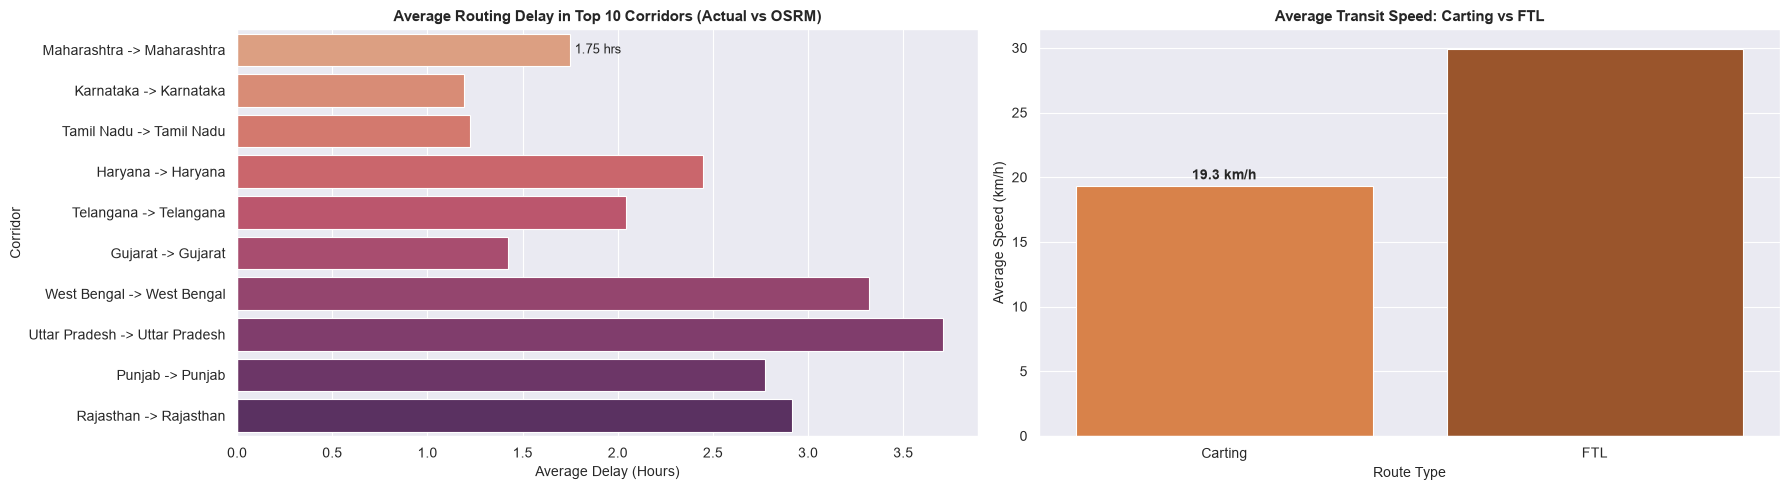

In [48]:
n_rows = 1
n_cols = 2
plt.figure(figsize=(18, 5 * n_rows))

# Plot 1: Average Delay across Top 10 Corridors
plt.subplot(n_rows, n_cols, 1)
ax1 = sns.barplot(
    x=corridor_stats['avg_delay_hrs'], 
    y=corridor_stats.index, 
    palette='flare'
)
ax1.bar_label(ax1.containers[0], fmt='%.2f hrs', padding=3, fontsize=9)
plt.title('Average Routing Delay in Top 10 Corridors (Actual vs OSRM)', fontsize=11, fontweight='bold')
plt.xlabel('Average Delay (Hours)')
plt.ylabel('Corridor')


# Plot 2: Average Transit Speed (Carting vs FTL) 
plt.subplot(n_rows, n_cols, 2)
# Compute overall effective speed: Total Distance (km) / Total Time (hrs)
speed_stats = (
    trip_df.groupby('route_type')['actual_distance_to_destination'].sum() / 
    (trip_df.groupby('route_type')['actual_time'].sum() / 60)
).reset_index(name='avg_speed_kmh')

ax2 = sns.barplot(
    x='route_type', 
    y='avg_speed_kmh', 
    data=speed_stats, 
    palette='Oranges_d'
)
ax2.bar_label(ax2.containers[0], fmt='%.1f km/h', padding=3, fontsize=10, fontweight='bold')
plt.title('Average Transit Speed: Carting vs FTL', fontsize=11, fontweight='bold')
plt.xlabel('Route Type')
plt.ylabel('Average Speed (km/h)')

plt.tight_layout()
plt.show()

### 8.4 Executive Business Insights

1. **Routing Engine Optimism (99.3% Failure Rate)**:
   - **99.3% of all trips took longer than OSRM predicted.**
   - OSRM computes shortest geometric paths. It ignores toll plazas, highway checkposts, city entry limits, and driver fatigue.

2. **Intra-State Movement Dominates the Network**:
   - The top 10 busiest corridors in India are all **intra-state** routes.
   - **Maharashtra -> Maharashtra** is the largest corridor (2,406 trips, 60.1 km average distance).
   - **Karnataka -> Karnataka** ranks second (2,015 trips, 55.0 km average distance).
   - Local delivery centers in Mumbai, Pune, and Bengaluru handle the highest freight density.

3. **Regional Transit Speed Disparities**:
   - **Slowest States**: Uttar Pradesh (17.8 km/h) and West Bengal (16.5 km/h). Drivers experience average delays of **3.3 to 3.7 hours per trip**.
   - **Fastest States**: Gujarat (28.2 km/h) and Tamil Nadu (27.5 km/h). Delays are lower (1.2 to 1.4 hours).
   - Regional road quality and border checks cause heavy operational drag in eastern corridors.

4. **Fleet Efficiency Disparity (FTL vs. Carting)**:
   - **Carting** handles 60.2% of trips. Average distance is 40.4 km, and average speed is **19.3 km/h**. Low speed is caused by city traffic and multiple sorting stops.
   - **FTL (Full Truck Load)** handles 39.8% of trips. Average distance is 351.9 km, and average speed is **29.9 km/h**. FTL bypasses intermediate hubs and moves faster on highways.

### 8.5 Actionable Recommendations for Executive Leadership

1. **Calibrate Dynamic Corridor Buffers on OSRM**:
   - **Finding**: 99.3% of shipments arrive later than the routing engine predicts.
   - **Action**: Stop using raw OSRM estimates for customer delivery promises. Add dynamic buffer times based on historical corridor delay. Add +45% extra buffer time for trips in Uttar Pradesh and West Bengal, but only +15% in Gujarat.

2. **Bypass Intermediate Hubs on Dense Urban Routes**:
   - **Finding**: Carting shuttles crawl at 19.3 km/h due to loading and unloading at multiple intermediate warehouses.
   - **Action**: Launch direct point-to-point mini-trucks between high-volume hubs (such as Bhiwandi to Mumbai, and Nelamangala to Bengaluru). Bypassing intermediate sorting centers will reduce transit times by 20% to 30%.

3. **Shift Dispatches to Night Hours in Congested States**:
   - **Finding**: Dispatches in Uttar Pradesh and West Bengal suffer the largest delays during daytime hours.
   - **Action**: Schedule line-haul truck departures between 10:00 PM and 5:00 AM in these regions. Night dispatches bypass daytime commercial vehicle restrictions and municipal traffic.

4. **Install GPS Geofencing at Warehouse Gates**:
   - **Finding**: A consistent 15-minute gap exists between physical gate arrival and manual barcode scanning.
   - **Action**: Set up automated GPS geofencing around warehouse yards. The system will clock in arriving trucks automatically when they cross the yard boundary, eliminating manual scan delay.